# Example 5.4 — Synthesis of Mechanisms with GA

## Minimization of $E_{\text{total}}$ with Grashof and Transmission Angle Constraints

**Chapter 5 — Four-bar mechanisms with genetic algorithms and neural networks**

This notebook implements a Genetic Algorithm (GA) to solve the synthesis problem, minimizing the following fitness function:

$$E_{\text{total}} = E_{\text{traj}} + W_1 \cdot P_G + W_2 \cdot P_{\text{TA}}$$

where:
- $E_{\text{traj}}$: trajectory error (averaged symmetrical Hausdorff distance)
- $P_G$: penalty for violating the Grashof condition
- $P_{\text{TA}}$: penalty for insufficient transmission angle ($\mu < 40°$)

**GA Parameters:** $N_{\text{pop}}=80$, $N_{\text{gen}}=250$, BLX-0.5 crossover, tournament selection of size 2, elitism.

**Search Domain:** $a \in [20,75]$ mm, $b \in [60,130]$ mm, $c \in [55,95]$ mm, $d=85$ mm (fixed).

In [1]:
from numpy import *
import matplotlib.pyplot as plt
import builtins
random.seed(42)

# Mechanism parameters
D_FIJO  = 85.0       # fixed link d (mm)
P_ARM   = 40.0       # coupler arm length p (mm)
DELTA   = pi/6       # delta coupler arm angle (rad)
GRASHOF_MARGIN = 3.0 # minimum margin for Grashof condition (mm)

# Target trajectory: coupling curve of the reference mechanism
# Reference: a=30 mm, b=78 mm, c=78 mm, d=85 mm
# Known properties: mu_min=41.3 degrees, Grashof margin approx 41 mm
A_REF=30.; B_REF=78.; C_REF=78.

def fourbar_coupler(a, b, c, d, th2, p=40., delta=pi/6):
    # Four-bar mechanism coupler position
    K1=d/a; K2=d/c; K3=(a**2-b**2+c**2+d**2)/(2*a*c)
    A=cos(th2)-K1-K2*cos(th2)+K3; B=-2*sin(th2)
    C=K1-(K2+1)*cos(th2)+K3
    K4=d/b; K5=(c**2-d**2-a**2-b**2)/(2*a*b)
    A2=cos(th2)-K1+K4*cos(th2)+K5; B2=-2*sin(th2)
    C2=K1+(K4-1)*cos(th2)+K5; disc2=B2**2-4*A2*C2
    th3=where(disc2>=0, 2*arctan2(-B2-sqrt(maximum(disc2,0)),2*A2), nan)
    return a*cos(th2)+p*cos(th3+delta), a*sin(th2)+p*sin(th3+delta)

def mu_eff_fn(a, b, c, d, th2):
    # Effective transmission angle (Shigley's law of cosines).
    # q^2 = d^2 + a^2 - 2*a*d*cos(th2)
    # cos(mu) = (b^2 + c^2 - q^2) / (2*b*c)  ->  mu_eff in [0, 90 degrees]
    q2 = d**2 + a**2 - 2.0*a*d*cos(th2)
    cos_mu = clip((b**2 + c**2 - q2) / (2.0*b*c), -1.0, 1.0)
    mu = arccos(cos_mu)
    return where(mu > pi/2, pi - mu, mu)

# Target points (20 reference mechanism positions)
t_ref = linspace(0, 2*pi, 20)
Pd_x, Pd_y = fourbar_coupler(A_REF, B_REF, C_REF, D_FIJO, t_ref, P_ARM, DELTA)

# GA parameters
MU_MIN  = radians(40.)   # minimum acceptable transmission angle
W1, W2  = 20.0, 15.0     # penalty weights (Grashof and angle)
N_POP=80; N_GEN=250; P_CRUZ=0.8; P_MUT=0.15
LB=array([20.,60.,55.]); UB=array([75.,130.,95.])

# Fitness function E_total
def E_total(x):
    a, b, c = x[0], x[1], x[2]; d = D_FIJO
    # Grashof Penalty
    lnks = sort([a, b, c, d])
    s, l = lnks[0], lnks[3]
    P_G  = maximum(0., s + l - (lnks[1]+lnks[2]) + GRASHOF_MARGIN) ** 2

    # Candidate coupling curve
    th2  = linspace(0, 2*pi, 72)
    Cx, Cy = fourbar_coupler(a, b, c, d, th2, P_ARM, DELTA)
    m = isfinite(Cx)
    if m.sum() < 10:
        return 1e4 + W1*P_G
    Cx2, Cy2 = Cx[m], Cy[m]

    # Trajectory error (averaged symmetrical Hausdorff)
    D  = sqrt((Cx2[:,None]-Pd_x[None,:])**2 + (Cy2[:,None]-Pd_y[None,:])**2)
    E_traj = D.min(0).mean() + D.min(1).mean()

    # Transmission angle penalty
    mu = mu_eff_fn(a, b, c, d, th2)
    viol = maximum(0., MU_MIN - mu)
    P_TA = viol.max()**2 + viol.mean()**2
    return E_traj + W1*P_G + W2*P_TA

# Evolution
pop = random.rand(N_POP, 3) * (UB-LB) + LB
hist_best = []

for gen in range(N_GEN):
    fitness = array([E_total(ind) for ind in pop])
    best_idx = fitness.argmin()
    hist_best.append(fitness[best_idx])
    nueva_pop = [pop[best_idx].copy()]                  # elitism
    while len(nueva_pop) < N_POP:
        idx = random.choice(N_POP, 4, replace=False)
        p1 = pop[idx[:2][fitness[idx[:2]].argmin()]]    # tournament 2
        p2 = pop[idx[2:][fitness[idx[2:]].argmin()]]
        if random.rand() < P_CRUZ:                      # crossover BLX-0.5
            alpha = 0.5
            lo = minimum(p1,p2)-alpha*abs(p1-p2)
            hi = maximum(p1,p2)+alpha*abs(p1-p2)
            hijo = random.rand(3)*(hi-lo)+lo
        else:
            hijo = p1.copy() if random.rand()<0.5 else p2.copy()
        if random.rand() < P_MUT:                       # Gaussian mutation
            hijo += random.randn(3)*(UB-LB)*0.05
        nueva_pop.append(clip(hijo, LB, UB))
    pop = array(nueva_pop)

# Optimal solution
fitness_final = array([E_total(ind) for ind in pop])
best = pop[fitness_final.argmin()]
a_opt, b_opt, c_opt = best

th2f = linspace(0, 2*pi, 360)
Cx_o, Cy_o = fourbar_coupler(a_opt, b_opt, c_opt, D_FIJO, th2f, P_ARM, DELTA)
v = isfinite(Cx_o)
D_f = sqrt((Cx_o[v,None]-Pd_x[None,:])**2 + (Cy_o[v,None]-Pd_y[None,:])**2)
haus_opt = builtins.max(D_f.min(0).max(), D_f.min(1).max())

Cx_i,Cy_i = fourbar_coupler(60.,90.,70.,D_FIJO,th2f,P_ARM,DELTA)
vi=isfinite(Cx_i)
D_fi=sqrt((Cx_i[vi,None]-Pd_x[None,:])**2+(Cy_i[vi,None]-Pd_y[None,:])**2)
haus_ini=builtins.max(D_fi.min(0).max(), D_fi.min(1).max())

mu_d = degrees(mu_eff_fn(a_opt, b_opt, c_opt, D_FIJO, th2f))
crit = (mu_d < 40) & isfinite(mu_d)
lnks = sort([a_opt, b_opt, c_opt, D_FIJO])
margen = lnks[1]+lnks[2]-lnks[0]-lnks[3]
grashof = margen > 0

print(f"GA Completed ({N_GEN} generations, {N_POP} individuals)")
print(f"Reference Mechanism : a={A_REF:.0f} mm, b={B_REF:.0f} mm, c={C_REF:.0f} mm, d={D_FIJO:.0f} mm")
print(f"GA Optimal Solution : a={a_opt:.2f} mm, b={b_opt:.2f} mm, c={c_opt:.2f} mm, d={D_FIJO:.0f} mm")
print(f"Minimum E_total     : {hist_best[-1]:.4f}")
print(f"Initial Hausdorff (a=60,b=90,c=70): {haus_ini:.2f} mm")
print(f"Optimal Hausdorff                 : {haus_opt:.2f} mm")
print(f"Min mu_eff          : {nanmin(mu_d):.2f} degrees")
print(f"Max mu_eff          : {nanmax(mu_d):.2f} degrees")
print(f"Mean mu_eff         : {nanmean(mu_d):.2f} degrees")
print(f"Critical Positions (mu < 40 degrees): {crit.sum()} / {v.sum()}")
print(f"Grashof Condition   : {'Satisfied' if grashof else 'NOT Satisfied'}  (margin={margen:.2f} mm)")

GA Completed (250 generations, 80 individuals)
Reference Mechanism : a=30 mm, b=78 mm, c=78 mm, d=85 mm
GA Optimal Solution : a=30.02 mm, b=77.85 mm, c=77.91 mm, d=85 mm
Minimum E_total     : 2.7203
Initial Hausdorff (a=60,b=90,c=70): 58.79 mm
Optimal Hausdorff                 : 6.43 mm
Min mu_eff          : 41.34 degrees
Max mu_eff          : 89.92 degrees
Mean mu_eff         : 68.03 degrees
Critical Positions (mu < 40 degrees): 0 / 360
Grashof Condition   : Satisfied  (margin=40.74 mm)


## Viewing Results

The graphs show:
- **(a)** GA Convergence: evolution of the best individual's $E_{\text{total}}$ per generation (semilogarithmic scale).
- **(b)** Trajectory Comparison: reference (black dashed line), initial point (red dash-dot line), and optimal GA solution (blue solid line).

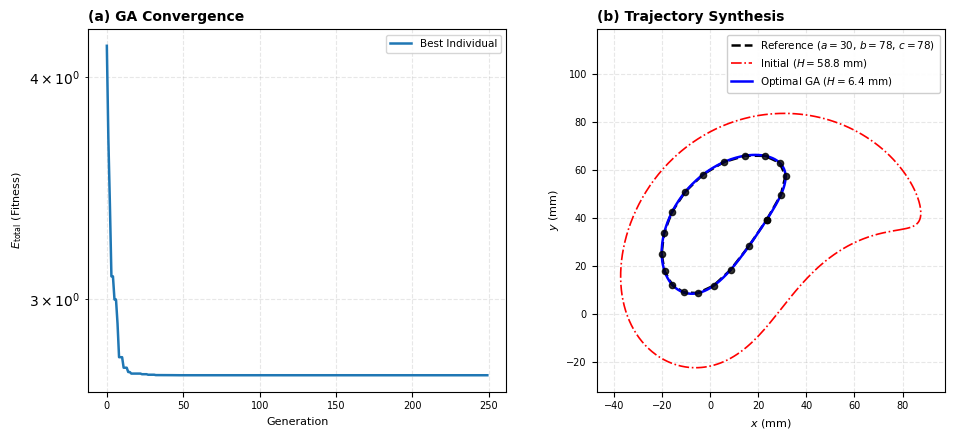

Figure successfully exported to vector PDF and high-res PNG as: Figure_5_4_ga_synthesis_etotal_complete


In [4]:
import os
import glob
import builtins
import matplotlib.pyplot as plt
from numpy import nanmin, nanmax

# 1. Automated Naming Setup
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "Figure_5_4_ga_synthesis_etotal_complete"
except Exception:
    notebook_name = "Figure_5_4_ga_synthesis_etotal_complete"

# 2. Springer Publication Style Adjustments
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans', 'sans-serif']

# Define font sizes
title_size = 10
label_size = 8
legend_size = 7.5
tick_size = 7

# Create figure for horizontal subplots
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

# --- Subplot (a): GA Convergence ---
ax1 = axes[0]
ax1.semilogy(hist_best, color='#1f77b4', lw=1.8, label='Best Individual')
ax1.set_xlabel("Generation", fontsize=label_size)
ax1.set_ylabel("$E_{\\mathrm{total}}$ (Fitness)", fontsize=label_size)
ax1.set_title("(a) GA Convergence", fontsize=title_size, fontweight='bold', loc='left')
ax1.tick_params(axis='both', labelsize=tick_size)
ax1.grid(True, which='both', linestyle='--', alpha=0.3)
ax1.legend(fontsize=legend_size, loc='upper right')

# --- Subplot (b): Trajectory Comparison ---
ax2 = axes[1]
ax2.plot(Pd_x, Pd_y, 'k--', lw=1.8, label='Reference ($a=30$, $b=78$, $c=78$)')
ax2.plot(Cx_i[vi], Cy_i[vi], 'r-.', lw=1.2, label=f'Initial ($H={haus_ini:.1f}$ mm)')
ax2.plot(Cx_o[v],  Cy_o[v],  'b-',  lw=1.8, label=f'Optimal GA ($H={haus_opt:.1f}$ mm)')
ax2.scatter(Pd_x, Pd_y, c='black', s=20, zorder=5, alpha=0.8)

ax2.set_xlabel("$x$ (mm)", fontsize=label_size)
ax2.set_ylabel("$y$ (mm)", fontsize=label_size)
ax2.set_title("(b) Trajectory Synthesis", fontsize=title_size, fontweight='bold', loc='left')
ax2.tick_params(axis='both', labelsize=tick_size)
ax2.set_aspect('equal', adjustable='box')
ax2.grid(True, linestyle='--', alpha=0.3)

# Safe minimum and maximum calculations avoiding conflicts
x_min = builtins.min(nanmin(Pd_x), nanmin(Cx_i[vi]), nanmin(Cx_o[v]))
x_max = builtins.max(nanmax(Pd_x), nanmax(Cx_i[vi]), nanmax(Cx_o[v]))
y_min = builtins.min(nanmin(Pd_y), nanmin(Cy_i[vi]), nanmin(Cy_o[v]))
y_max = builtins.max(nanmax(Pd_y), nanmax(Cy_i[vi]), nanmax(Cy_o[v]))

# Prevent label clipping by expanding bounds slightly
ax2.set_xlim(x_min - 10, x_max + 10)
ax2.set_ylim(y_min - 10, y_max + 35) # Expanded top margin to accommodate the legend safely

ax2.legend(fontsize=legend_size, loc='upper right', framealpha=0.95)

plt.tight_layout()

# 3. Export Double Obligatoria
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()

print(f"Figure successfully exported to vector PDF and high-res PNG as: {notebook_name}")